<a href="https://colab.research.google.com/github/Joyanne05/vres-sentiment-analysis/blob/main/sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [9]:
df = pd.read_csv("course_data_clean.csv")
df = df[["reviews", "course_rating_int"]]
df.head()

,reviews,course_rating_int
0,go to office hours and practice,1.0
1,One of my least favourite courses. Although th...,0.0
2,It starts with a very low pace but after midte...,0.0
3,Took this in 2018 with no programming experien...,1.0
4,I loved everything about cs 115. Great instruc...,1.0


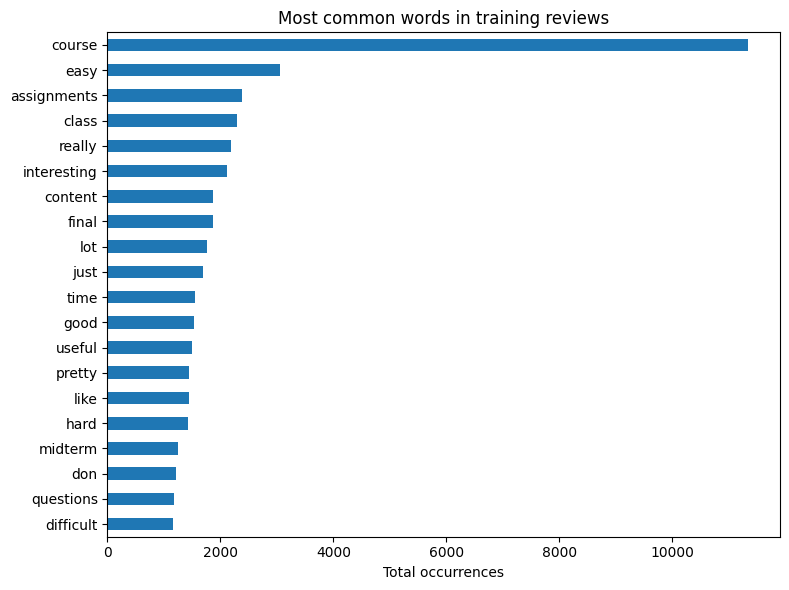

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

explore_df = pd.DataFrame({
    "review": X_train.to_numpy(),
    "label": y_train.to_numpy()
})

counter = CountVectorizer(stop_words="english")

counts = counter.fit_transform(explore_df["review"])

word_counts = pd.Series(
    counts.sum(axis=0).A1,
    index=counter.get_feature_names_out()
).sort_values(ascending=False)

word_counts.head(20).sort_values().plot.barh(figsize=(8, 6))
plt.xlabel("Total occurrences")
plt.title("Most common words in training reviews")
plt.tight_layout()
plt.show()

In [11]:
print(df["course_rating_int"].value_counts(dropna=False))

course_rating_int
1.0    9786
0.0    4830
NaN     222
Name: count, dtype: int64


In [13]:
# Remove rows missing a review or rating
df = df.dropna(subset=["reviews", "course_rating_int"]).copy()

# Remove empty or whitespace-only reviews
df = df[df["reviews"].str.strip().ne("")].copy()

# Convert labels to integer
df["course_rating_int"] = df["course_rating_int"].astype(int)

# Check the result
print(df["course_rating_int"].value_counts(dropna=False))
print("Remaining rows:", len(df))

course_rating_int
1    9784
0    4824
Name: count, dtype: int64
Remaining rows: 14608


In [14]:
# Split dataset (80/20)
X = df["reviews"]
y = df["course_rating_int"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [27]:
# Vectorisation using TF-IDF
vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)


Training matrix: (11686, 12366)
Test matrix: (2922, 12366)


In [26]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [28]:
y_pred = lr_model.predict(X_test_tfidf)

In [29]:
from sklearn.metrics import accuracy_score, classification_report

print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

Accuracy: 0.776
              precision    recall  f1-score   support

    Negative       0.76      0.47      0.58       965
    Positive       0.78      0.93      0.85      1957

    accuracy                           0.78      2922
   macro avg       0.77      0.70      0.71      2922
weighted avg       0.77      0.78      0.76      2922



In [30]:
# Multinomial Naive Bayes
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

In [31]:
from sklearn.metrics import accuracy_score, classification_report

print(f"Accuracy: {accuracy_score(y_test, nb_pred):.3f}")

print(classification_report(
    y_test,
    nb_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

Accuracy: 0.708
              precision    recall  f1-score   support

    Negative       0.96      0.12      0.22       965
    Positive       0.70      1.00      0.82      1957

    accuracy                           0.71      2922
   macro avg       0.83      0.56      0.52      2922
weighted avg       0.78      0.71      0.62      2922



In [32]:
# Support Vector Machine
from sklearn.svm import LinearSVC

svm_model = LinearSVC()
svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

print(f"Accuracy: {accuracy_score(y_test, svm_pred):.3f}")

print(classification_report(
    y_test,
    svm_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

Accuracy: 0.765
              precision    recall  f1-score   support

    Negative       0.68      0.55      0.61       965
    Positive       0.80      0.87      0.83      1957

    accuracy                           0.76      2922
   macro avg       0.74      0.71      0.72      2922
weighted avg       0.76      0.76      0.76      2922



In [35]:
import pandas as pd

baseline_results = pd.DataFrame({
    "model": ["Logistic Regression", "Multinomial Naive Bayes", "Linear SVM"],
    "accuracy": [0.776, 0.708, 0.765],
    "macro_f1": [0.71, 0.52, 0.72],
    "negative_recall": [0.47, 0.12, 0.55]
})

baseline_results.to_csv("baseline_results.csv", index=False)
baseline_results

,model,accuracy,macro_f1,negative_recall
0,Logistic Regression,0.776,0.71,0.47
1,Multinomial Naive Bayes,0.708,0.52,0.12
2,Linear SVM,0.765,0.72,0.55


## Cross validation

In [36]:
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import make_scorer, recall_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [37]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(random_state=42)
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "negative_recall": make_scorer(
        recall_score,
        pos_label=0,
        zero_division=0
    )
}

In [41]:
cv_results = {}
summary = []

for name, model in models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer()),
        ("clf", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    cv_results[name] = scores

    summary.append({
        "model": name,
        "accuracy_mean": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "macro_f1_mean": scores["test_macro_f1"].mean(),
        "macro_f1_std": scores["test_macro_f1"].std(),
        "negative_recall_mean": scores["test_negative_recall"].mean()
    })

cv_summary = pd.DataFrame(summary)
print("5-fold cross-validation with fixed model settings")
display(cv_summary.round(3))

5-fold cross-validation with fixed model settings


,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,negative_recall_mean
0,Logistic Regression,0.785,0.010,0.729,0.012,0.500
1,Naive Bayes,0.707,0.003,0.518,0.009,0.123
2,Linear SVM,0.773,0.007,0.732,0.008,0.574


In [51]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {
        "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
        "tfidf__min_df": [1, 2, 5],
        "clf__C": [0.1, 1, 10],
        "clf__class_weight": [None, "balanced"]
    },

    "Naive Bayes": {
        "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
        "tfidf__min_df": [1, 2, 5],
        "clf__alpha": [0.1, 0.5, 1, 2]
    },

    "Linear SVM": {
        "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
        "tfidf__min_df": [1, 2, 5],
        "clf__C": [0.1, 1, 10],
        "clf__class_weight": [None, "balanced"]
    }
}

In [52]:
searches = {}
tuning_summary = []

for name, model in models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer()),
        ("clf", model)
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring=scoring,
        refit="macro_f1",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        error_score="raise"
    )

    search.fit(X_train, y_train)
    searches[name] = search

    best_index = search.best_index_
    results = search.cv_results_

    tuning_summary.append({
        "model": name,
        "cv_accuracy": results["mean_test_accuracy"][best_index],
        "cv_macro_f1": results["mean_test_macro_f1"][best_index],
        "cv_macro_f1_std": results["std_test_macro_f1"][best_index],
        "cv_negative_recall": results["mean_test_negative_recall"][best_index],
        "best_params": search.best_params_
    })

    print(f"\n{name}")
    print("Best settings:", search.best_params_)
    print(f"Best CV macro-F1: {search.best_score_:.3f}")

tuned_results = pd.DataFrame(tuning_summary)

display(tuned_results.drop(columns="best_params").round(3))

Fitting 5 folds for each of 54 candidates, totalling 270 fits

Logistic Regression
Best settings: {'clf__C': 10, 'clf__class_weight': 'balanced', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 3)}
Best CV macro-F1: 0.760
Fitting 5 folds for each of 36 candidates, totalling 180 fits

Naive Bayes
Best settings: {'clf__alpha': 0.1, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 3)}
Best CV macro-F1: 0.734
Fitting 5 folds for each of 54 candidates, totalling 270 fits

Linear SVM
Best settings: {'clf__C': 1, 'clf__class_weight': 'balanced', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 3)}
Best CV macro-F1: 0.759


,model,cv_accuracy,cv_macro_f1,cv_macro_f1_std,cv_negative_recall
0,Logistic Regression,0.792,0.760,0.011,0.650
1,Naive Bayes,0.787,0.734,0.006,0.517
2,Linear SVM,0.792,0.759,0.010,0.637


In [42]:
from sklearn.model_selection import cross_val_predict

best_lr = searches["Logistic Regression"].best_estimator_

oof_pred = cross_val_predict(
    best_lr,
    X_train,       # Raw review text
    y_train,
    cv=cv,         # Your existing five-fold splitter
    method="predict",
    n_jobs=-1
)

In [43]:
error_analysis = pd.DataFrame({
    "review": X_train.to_numpy(),
    "actual": y_train.to_numpy(),
    "predicted": oof_pred
})

mistakes = error_analysis[
    error_analysis["actual"] != error_analysis["predicted"]
].copy()

print("Number of misclassified reviews:", len(mistakes))

Number of misclassified reviews: 2478


In [44]:
sample = mistakes.sample(
    n=min(10, len(mistakes)),
    random_state=42
)

for index, row in sample.iterrows():
    print("Row:", index)
    print("Review:", row["review"])
    print("Actual label:", row["actual"])
    print("Model prediction:", row["predicted"])
    print()

Row: 8340
Review: Keep up with the weekly assignments and you'll be okay. Half the stuff wasn't taught at my high school calculus. Don't think you'll know it because you took high school calc. Everyone did.
Actual label: 1
Model prediction: 0

Row: 1354
Review: Easy 90, just get the participation marks
Actual label: 1
Model prediction: 0

Row: 9757
Review: I am not a math person, but I found this on the easier side. Sometimes the lectures went through fast so you had to review a lot on your own time.
Actual label: 0
Model prediction: 1

Row: 4793
Review: another shitty 1st year chem.
Actual label: 0
Model prediction: 1

Row: 265
Review: This course is meh. Not that hard, but also not that useful. The entire course is basically 3 interviews that are different types. Prof Doyle is reasonable with extensions and is flexible, but also grades a bit tuff. if you want an easy 80+, this course is good. Other than that, you don't learn much and nor is it very interesting.
Actual label: 0
Model 

In [53]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report
)

test_results = []
test_predictions = {}

for name, search in searches.items():
    best_model = search.best_estimator_

    # Pass raw review text, not X_test_tfidf
    predictions = best_model.predict(X_test)
    test_predictions[name] = predictions

    test_results.append({
        "model": name,
        "test_accuracy": accuracy_score(y_test, predictions),
        "test_macro_f1": f1_score(
            y_test, predictions, average="macro"
        ),
        "test_negative_recall": recall_score(
            y_test, predictions, pos_label=0, zero_division=0
        )
    })

    print(f"\n{name}")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

test_summary = pd.DataFrame(test_results)
display(test_summary.round(3))


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.69      0.62      0.66       965
    Positive       0.82      0.87      0.84      1957

    accuracy                           0.78      2922
   macro avg       0.76      0.74      0.75      2922
weighted avg       0.78      0.78      0.78      2922


Naive Bayes
              precision    recall  f1-score   support

    Negative       0.77      0.49      0.60       965
    Positive       0.79      0.93      0.85      1957

    accuracy                           0.78      2922
   macro avg       0.78      0.71      0.72      2922
weighted avg       0.78      0.78      0.77      2922


Linear SVM
              precision    recall  f1-score   support

    Negative       0.70      0.61      0.65       965
    Positive       0.82      0.87      0.85      1957

    accuracy                           0.79      2922
   macro avg       0.76      0.74      0.75      2922
weighted avg       0.78     

,model,test_accuracy,test_macro_f1,test_negative_recall
0,Logistic Regression,0.785,0.750,0.622
1,Naive Bayes,0.782,0.723,0.486
2,Linear SVM,0.787,0.750,0.610
